# Semana 2 · Vetorização, parte 1

**Pergunta da aula:** como calcular uma previsão quando cada exemplo tem várias características?

Na semana 1, uma casa era representada pela área e a previsão era `w * area + b`. Agora imagine que conhecemos a área, a quantidade de quartos e a idade da casa. Cada característica ganha seu próprio peso. Nesta prática, vamos usar os três números do slide, sem atribuir unidades a eles, para acompanhar a conta inteira.

Adaptação da aula *Vetorização – parte 1* e do laboratório *Python, NumPy and Vectorization*, da Machine Learning Specialization (Andrew Ng, DeepLearning.AI e Stanford Online). As saídas já aparecem no GitHub. Para experimentar, abra no Colab e execute as células de cima para baixo.

## 1. Quem é quem na previsão?

`x` guarda as características **de um único exemplo**. `w` guarda um peso para cada característica, na mesma ordem. `b` é um único valor somado ao final. Nesta aula os pesos já vêm prontos. A tarefa é usá-los para prever.

`np.array(...)` recebe uma sequência de números e devolve um array do NumPy. Aqui, cada array tem uma dimensão. O índice seleciona qual número queremos ler: o primeiro peso, chamado $w_1$ no slide, é `w[0]` em Python.

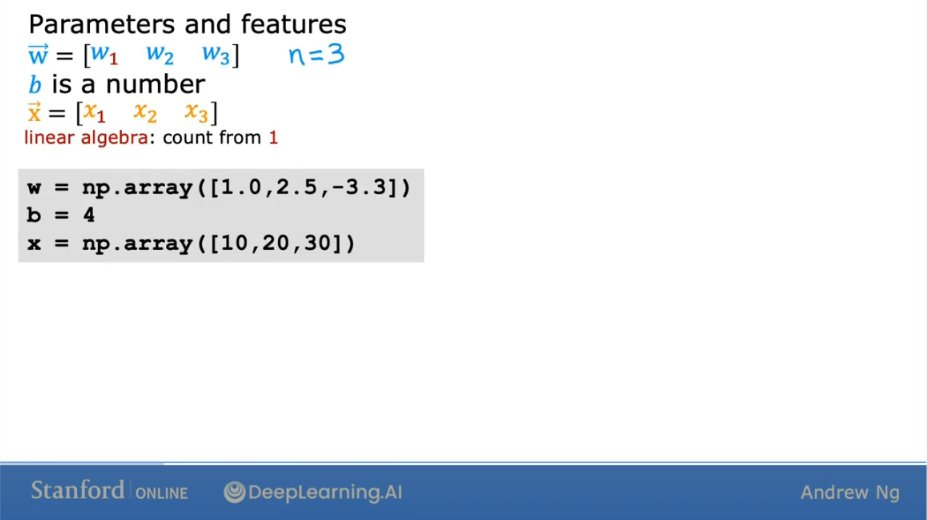

In [1]:
import numpy as np  # np é o nome curto que usamos para chamar o NumPy.

x = np.array([10, 20, 30])
w = np.array([1.0, 2.5, -3.3])
b = 4

print("Formato de x:", x.shape)
print("Primeiro par:", w[0], "×", x[0])

Formato de x: (3,)
Primeiro par: 1.0 × 10


O formato `(3,)` indica um vetor com três posições. Repare na ordem dos pares: 1,0 acompanha 10, 2,5 acompanha 20 e −3,3 acompanha 30.

## 2. Faça a previsão à mão

Multiplique cada entrada pelo peso que ocupa a mesma posição. O peso negativo faz a terceira característica diminuir a previsão.

| Índice em Python | Conta | Parcela | Soma até aqui |
|---:|---|---:|---:|
| 0 | 1,0 × 10 | 10 | 10 |
| 1 | 2,5 × 20 | 50 | 60 |
| 2 | −3,3 × 30 | −99 | −39 |

O slide usa o símbolo $\sum$ para pedir essa soma. Ainda falta acrescentar `b`: −39 + 4 = **−35**. Veja como a fórmula fica quando escrevemos cada parcela em Python.

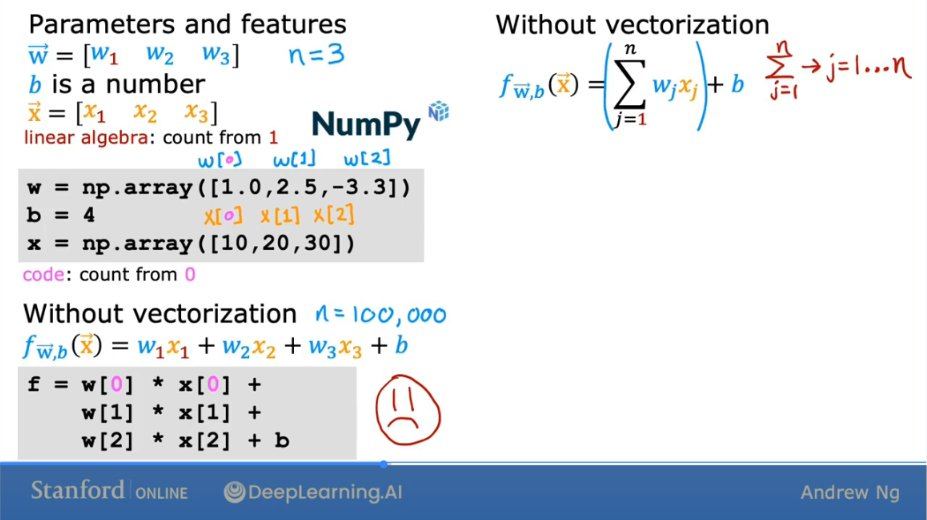

In [2]:
previsao_manual = w[0] * x[0] + w[1] * x[1] + w[2] * x[2] + b
print("Previsão:", previsao_manual)

Previsão: -35.0


## 3. Como repetir a mesma conta para qualquer quantidade de características?

A função `produto_escalar` recebe dois vetores de mesmo comprimento e devolve a soma dos produtos dos pares. Esse resultado é chamado de **produto escalar**. No laboratório original, a função se chama `my_dot`.

Começamos com a soma em zero. `len(entradas)` conta as posições, e `range(3)` faz o índice passar por 0, 1 e 2. A cada volta, `+=` acrescenta a parcela à soma anterior. O `return` fica fora do laço para devolver a soma depois das três voltas.

In [3]:
def produto_escalar(pesos, entradas):
    soma = 0.0
    for j in range(len(entradas)):
        parcela = pesos[j] * entradas[j]
        soma += parcela
    return soma

produto = produto_escalar(w, x)
print("Produto escalar:", produto)
print("Previsão com o laço:", produto + b)

Produto escalar: -39.0
Previsão com o laço: -35.0


## 4. A linha principal da aula

**`np.dot(w, x) + b`** calcula a previsão. Para esses dois vetores, `np.dot` recebe os pesos e as entradas, multiplica os pares e soma os produtos. Devolve um número: −39. O `+ b` acrescenta 4 uma única vez.

Isso é vetorização neste exemplo: entregamos os vetores inteiros a uma operação do NumPy. O trabalho de percorrer os elementos acontece dentro da biblioteca. Assim podemos usar a mesma linha com três ou com milhares de características.

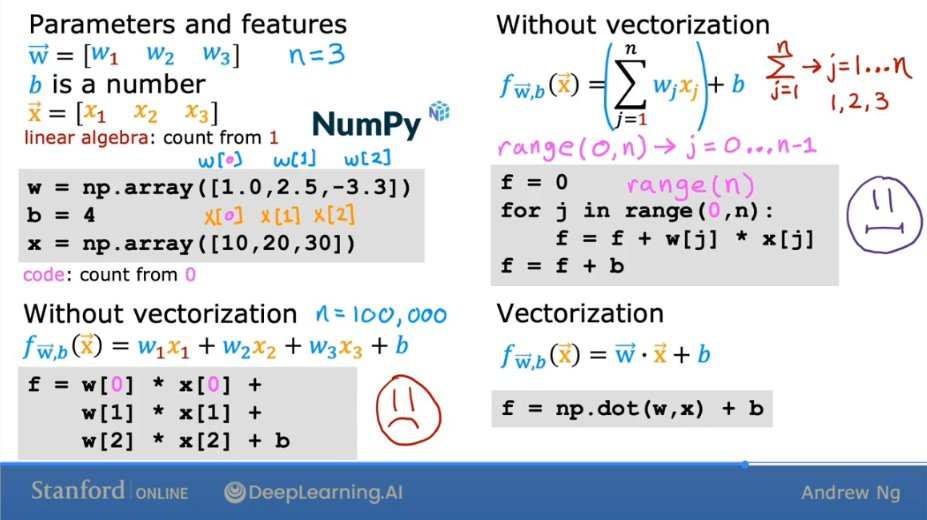

In [4]:
parcelas = w * x            # Multiplica posição por posição e guarda três números.
produto = np.dot(w, x)      # Multiplica os pares e soma; devolve um número.
previsao = produto + b      # Acrescenta o termo fixo uma vez.

print("Parcelas:", parcelas)
print("Soma das parcelas:", produto)
print("Previsão vetorizada:", previsao)

Parcelas: [ 10.  50. -99.]
Soma das parcelas: -38.99999999999999
Previsão vetorizada: -34.99999999999999


### Confira com outro exemplo do laboratório

Aqui os nomes `a` e `v` representam apenas dois vetores. Faça a conta antes de executar: $1×(-1) + 2×4 + 3×3 + 4×2$. A função que escrevemos com o laço e a função do NumPy devem devolver **24**.

In [5]:
a = np.array([1, 2, 3, 4])
v = np.array([-1, 4, 3, 2])

print("Com o laço:", produto_escalar(a, v))
print("Com NumPy:", np.dot(a, v))

Com o laço: 24.0
Com NumPy: 24


**Para testar se entendeu:** volte à primeira célula e troque apenas `x[2]` de 30 para 31 na criação do vetor. Qual parcela muda? Como o terceiro peso vale −3,3, acrescentar uma unidade à terceira entrada reduz a previsão em 3,3. Execute novamente as células e confira se o resultado passa de −35 para **−38,3**.